# Análisis de sentimiento en reseñas

**WeLoveReviews · Harbor House Café**

## Objetivos

La pregunta no es si el negocio tiene buenas estrellas: el rating medio observado es exactamente **4,5/5**. Queremos saber si el lenguaje escrito cuenta la misma historia en las 500 reseñas, cuantificar la proporción positiva, neutral y negativa, y encontrar dónde el modelo discrepa de la puntuación humana.

Usaremos un modelo ya entrenado, no ajustaremos pesos. Sus predicciones se contrastarán con ratings y con una revisión cualitativa; no se presentarán como verdad absoluta.

## 1. Crear y verificar la rama de trabajo

La rama se creó antes de comenzar el notebook. Esta celda verifica su nombre y registra el estado; no vuelve a crearla.

## 2. Instalar dependencias y verificar el entorno

Las dependencias están fijadas en `requirements.txt` para inferencia y en `requirements-eda.txt` para las métricas/gráficas del notebook. Desde la raíz de esta feature: `python -m pip install -r requirements.txt -r requirements-eda.txt`. Se usa CPU para mantener el entorno reproducible y evitar CUDA.

In [1]:
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

branch = subprocess.run(
    ["git", "branch", "--show-current"], capture_output=True, text=True, check=True
).stdout.strip()
status = subprocess.run(
    ["git", "status", "--short", "--branch"], capture_output=True, text=True, check=True
).stdout.strip()
print("Python:", sys.executable)
print("Rama activa:", branch)
print(status)
assert branch == "feature/analisis-sentimiento"

packages = ["pandas", "numpy", "scikit-learn", "transformers", "torch", "matplotlib", "seaborn"]
for package in packages:
    try:
        print(f"{package}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package}: no instalado en este kernel")

Python: /workspaces/franco-beron-ai-engineering-company-project-monorepo/services/support-api/.venv/bin/python
Rama activa: feature/analisis-sentimiento
## feature/analisis-sentimiento
?? ../
pandas: 2.3.2
numpy: 2.2.6
scikit-learn: 1.7.2
transformers: 4.53.3
torch: 2.7.1+cpu
matplotlib: 3.10.6
seaborn: 0.13.2


## 3. Importar librerías y parámetros globales

Las rutas se resuelven desde la carpeta del proyecto para que el notebook funcione tanto si Jupyter abre desde `src/` como desde la raíz del monorepo. La revisión del modelo es un commit inmutable.

In [2]:
import json
import random
import re
import subprocess
import sys
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

SEED = 42
SAMPLE_SIZE = 20
BATCH_SIZE = 8
MODEL_ID = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"
RATING_COLUMN = "rating"
TEXT_COLUMN = "review_text"

random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (parent for parent in (cwd, *cwd.parents) if (parent / "data/raw/reviews.csv").exists()),
    Path("..").resolve(),
)
INPUT_PATH = PROJECT_ROOT / "data/raw/reviews.csv"
OUTPUT_PATH = PROJECT_ROOT / "data/processed/reviews_with_sentiment.csv"
REPORTS_PATH = PROJECT_ROOT / "reports"
FIGURES_PATH = REPORTS_PATH / "figures"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

print("Proyecto:", PROJECT_ROOT)
print("Entrada:", INPUT_PATH)
print("Salida:", OUTPUT_PATH)
print("Python:", sys.version.split()[0])
for package in ("pandas", "numpy", "scikit-learn", "transformers", "torch", "matplotlib", "seaborn"):
    from importlib.metadata import version
    print(f"{package}: {version(package)}")

Proyecto: /workspaces/franco-beron-ai-engineering-company-project-monorepo/data/pipelines/analisis-sentimiento
Entrada: /workspaces/franco-beron-ai-engineering-company-project-monorepo/data/pipelines/analisis-sentimiento/data/raw/reviews.csv
Salida: /workspaces/franco-beron-ai-engineering-company-project-monorepo/data/pipelines/analisis-sentimiento/data/processed/reviews_with_sentiment.csv
Python: 3.12.1
pandas: 2.3.2
numpy: 2.2.6
scikit-learn: 1.7.2
transformers: 4.53.3
torch: 2.7.1+cpu
matplotlib: 3.10.6
seaborn: 0.13.2


## 4. Cargar el dataset de reseñas

Primero validamos el contrato del CSV. La muestra y los conteos de calidad permiten distinguir problemas reales de limpieza de transformaciones innecesarias.

In [3]:
df_raw = pd.read_csv(INPUT_PATH)
REQUIRED_COLUMNS = {"review_id", RATING_COLUMN, TEXT_COLUMN}
missing_columns = REQUIRED_COLUMNS - set(df_raw.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing_columns)}")

print("Forma:", df_raw.shape)
print("Tipos:")
display(df_raw.dtypes.rename("dtype").to_frame())
print("Nulos por columna:")
display(df_raw.isna().sum().rename("missing").to_frame())
print("Primeras reseñas:")
display(df_raw.head())
print("Resumen del dataset:")
df_raw.info()
print("Ratings:")
display(df_raw[RATING_COLUMN].value_counts().sort_index().rename("count").to_frame())
print("Media rating:", round(df_raw[RATING_COLUMN].mean(), 2))
print("IDs duplicados:", int(df_raw["review_id"].duplicated().sum()))
print("Textos duplicados exactos:", int(df_raw[TEXT_COLUMN].duplicated().sum()))

Forma: (500, 3)
Tipos:


,dtype
review_id,int64
rating,int64
review_text,object


Nulos por columna:


,missing
review_id,0
rating,0
review_text,0


Primeras reseñas:


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...
3,4,5,Visited Harbor House Café last weekend. The st...
4,5,5,Grabbed a quick coffee at Harbor House Café th...


Resumen del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    500 non-null    int64 
 1   rating       500 non-null    int64 
 2   review_text  500 non-null    object
dtypes: int64(2), object(1)
memory usage: 11.8+ KB
Ratings:


,count
rating,
1,12
2,18
3,38
4,72
5,360


Media rating: 4.5
IDs duplicados: 0
Textos duplicados exactos: 7


## 5. Limpieza y preprocesamiento de texto

Hay siete textos repetidos, pero pertenecen a IDs de reseña distintos. Los conservamos para no borrar observaciones; solo se deduplicaría un `review_id`. La normalización elimina ruido de formato sin quitar negaciones ni puntuación útil para el modelo.

In [4]:
import html

def normalize_review(text):
    value = unicodedata.normalize("NFKC", str(text))
    value = html.unescape(value)
    value = re.sub(r"<[^>]*>", " ", value)
    value = re.sub(r"[\x00-\x1f\x7f]", " ", value)
    return re.sub(r"\s+", " ", value).strip().lower()


df = df_raw.copy()
df["review_text_clean"] = df[TEXT_COLUMN].map(normalize_review)
df[RATING_COLUMN] = pd.to_numeric(df[RATING_COLUMN], errors="coerce")
quality_before = len(df)
df = df.dropna(subset=["review_id", RATING_COLUMN, "review_text_clean"])
df = df[df["review_text_clean"].str.len() > 0]
df = df.drop_duplicates(subset="review_id", keep="first").copy()
df[RATING_COLUMN] = df[RATING_COLUMN].astype(int)

print({
    "rows_before": quality_before,
    "rows_after": len(df),
    "rows_removed": quality_before - len(df),
    "duplicate_ids_removed": int(quality_before - len(df)),
    "exact_text_duplicates_preserved": int(df["review_text_clean"].duplicated().sum()),
})
assert len(df) == 500, "El análisis debe conservar las 500 reseñas oficiales"
display(df[["review_id", RATING_COLUMN, "review_text_clean"]].head())

{'rows_before': 500, 'rows_after': 500, 'rows_removed': 0, 'duplicate_ids_removed': 0, 'exact_text_duplicates_preserved': 7}


,review_id,rating,review_text_clean
0,1,5,visited harbor house café last weekend. great ...
1,2,5,tried harbor house café after seeing it recomm...
2,3,5,tried harbor house café after seeing it recomm...
3,4,5,visited harbor house café last weekend. the st...
4,5,5,grabbed a quick coffee at harbor house café th...


## 6. Análisis exploratorio mínimo e insights

La distribución de estrellas está muy concentrada arriba. Revisaremos también la longitud del texto: el desajuste entre rating y lenguaje será importante al interpretar falsos negativos, pero la puntuación por sí sola no valida el tono escrito.

Rating share (%):


,percent
rating,
1,2.4
2,3.6
3,7.6
4,14.4
5,72.0


Longitud de texto por rating:


,count,mean,median,min,max
rating,,,,,
1,12,175.3,179.5,128,230
2,18,151.3,156.0,87,175
3,38,152.7,158.0,86,200
4,72,182.3,186.0,115,230
5,360,170.4,172.0,92,227


/tmp/ipykernel_41466/588901820.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.head(2), include_groups=True)


,review_id,rating,review_text_clean
77,78,1,regular customer at harbor house café here. th...
99,100,1,came to harbor house café for a birthday brunc...
31,32,2,stopped by harbor house café for the first tim...
33,34,2,stopped by harbor house café for the first tim...
8,9,3,regular customer at harbor house café here. av...
15,16,3,stopped by harbor house café for the first tim...
13,14,4,tried harbor house café after seeing it recomm...
16,17,4,tried harbor house café after seeing it recomm...
0,1,5,visited harbor house café last weekend. great ...
1,2,5,tried harbor house café after seeing it recomm...


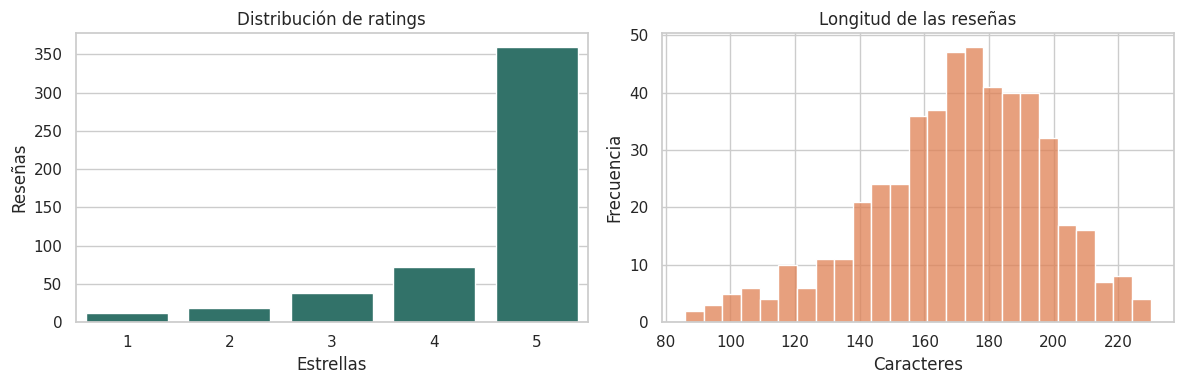

Insights comprobados:
- Rating medio: 4.50/5.
- Cinco estrellas: 72.0% de las reseñas.
- Ratings 1-2: 30 reseñas; el soporte de negativos es pequeño para evaluarlos con precisión.
- Longitud mediana: 173 caracteres; la variación de longitud puede afectar el truncamiento del modelo.


In [5]:
df["review_length_chars"] = df["review_text_clean"].str.len()
rating_counts = df[RATING_COLUMN].value_counts().sort_index()
length_summary = df.groupby(RATING_COLUMN)["review_length_chars"].agg(["count", "mean", "median", "min", "max"]).round(1)
print("Rating share (%):")
display((rating_counts / len(df) * 100).round(1).rename("percent").to_frame())
print("Longitud de texto por rating:")
display(length_summary)

examples_by_rating = (
    df.groupby(RATING_COLUMN, group_keys=False)
    .apply(lambda group: group.head(2), include_groups=True)
    [["review_id", RATING_COLUMN, "review_text_clean"]]
)
display(examples_by_rating)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, color="#287c70", ax=axes[0])
axes[0].set(title="Distribución de ratings", xlabel="Estrellas", ylabel="Reseñas")
sns.histplot(df["review_length_chars"], bins=25, color="#df8053", ax=axes[1])
axes[1].set(title="Longitud de las reseñas", xlabel="Caracteres", ylabel="Frecuencia")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_rating_and_length.png", dpi=140, bbox_inches="tight")
plt.show()

print("Insights comprobados:")
print(f"- Rating medio: {df[RATING_COLUMN].mean():.2f}/5.")
print(f"- Cinco estrellas: {(rating_counts.get(5, 0) / len(df)):.1%} de las reseñas.")
print(f"- Ratings 1-2: {int(rating_counts.reindex([1, 2], fill_value=0).sum())} reseñas; el soporte de negativos es pequeño para evaluarlos con precisión.")
print(f"- Longitud mediana: {df['review_length_chars'].median():.0f} caracteres; la variación de longitud puede afectar el truncamiento del modelo.")

## 7. Aplicar el modelo preentrenado

El candidato pedido es un clasificador de reseñas de productos de cinco estrellas. La fuente describe reseñas de servicios; esa diferencia de dominio se tratará como riesgo y se buscarán desacuerdos en vez de asumir que el modelo es correcto. Se carga una única pipeline antes de cualquier loop.

In [6]:
from transformers import pipeline

classifier = pipeline(
    "sentiment-analysis",
    model=MODEL_ID,
    revision=MODEL_REVISION,
    device=-1,
)
preview_texts = df["review_text_clean"].head(4).tolist()
preview_predictions = classifier(
    preview_texts,
    batch_size=4,
    truncation=True,
    max_length=512,
)
display(pd.DataFrame({
    "review_id": df["review_id"].head(4).tolist(),
    "rating": df[RATING_COLUMN].head(4).tolist(),
    "model_label": [prediction["label"] for prediction in preview_predictions],
    "score": [round(float(prediction["score"]), 4) for prediction in preview_predictions],
}))

/workspaces/franco-beron-ai-engineering-company-project-monorepo/services/support-api/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Device set to use cpu


,review_id,rating,model_label,score
0,1,5,5 stars,0.7170
1,2,5,5 stars,0.9822
2,3,5,5 stars,0.6623
3,4,5,5 stars,0.9895


## 8. Inferencia por lotes y mapeo de polaridad

El modelo entrega una categoría de 1–5 estrellas y su score de confianza. Mapeamos 1–2 a negativo, 3 a neutral y 4–5 a positivo; el rating humano se conserva en una columna separada. Una sola pipeline procesa todas las reseñas en lotes para limitar memoria.

In [7]:
STAR_TO_SENTIMENT = {1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"}

def parse_stars(label):
    match = re.search(r"([1-5])\s*stars?", label.lower())
    if match is None:
        raise ValueError(f"Etiqueta del modelo inesperada: {label!r}")
    return int(match.group(1))


inference_started = __import__("time").perf_counter()
texts = df["review_text_clean"].tolist()
model_outputs = []
for start in range(0, len(texts), BATCH_SIZE):
    batch = texts[start : start + BATCH_SIZE]
    model_outputs.extend(
        classifier(
            batch,
            batch_size=BATCH_SIZE,
            truncation=True,
            max_length=512,
        )
    )

assert len(model_outputs) == len(df) == 500

df_results = df[["review_id", RATING_COLUMN, TEXT_COLUMN, "review_text_clean"]].copy()
df_results["model_label"] = [result["label"] for result in model_outputs]
df_results["predicted_stars"] = [parse_stars(result["label"]) for result in model_outputs]
df_results["sentiment"] = df_results["predicted_stars"].map(STAR_TO_SENTIMENT)
df_results["score"] = [round(float(result["score"]), 6) for result in model_outputs]
df_results["human_sentiment"] = df_results[RATING_COLUMN].map(STAR_TO_SENTIMENT)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_results.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")
inference_seconds = __import__("time").perf_counter() - inference_started
sentiment_distribution = (
    df_results["sentiment"].value_counts().reindex(["positive", "neutral", "negative"], fill_value=0)
)
print(f"Procesadas {len(df_results)} reseñas en {inference_seconds:.1f} s")
print("Rating humano medio:", round(df_results[RATING_COLUMN].mean(), 2))
display(pd.DataFrame({"count": sentiment_distribution, "percent": (sentiment_distribution / len(df_results) * 100).round(1)}))
print("CSV guardado:", OUTPUT_PATH)
display(df_results[["review_id", RATING_COLUMN, "model_label", "sentiment", "score"]].head())

Procesadas 500 reseñas en 55.8 s
Rating humano medio: 4.5


,count,percent
sentiment,,
positive,412,82.4
neutral,41,8.2
negative,47,9.4


CSV guardado: /workspaces/franco-beron-ai-engineering-company-project-monorepo/data/pipelines/analisis-sentimiento/data/processed/reviews_with_sentiment.csv


,review_id,rating,model_label,sentiment,score
0,1,5,5 stars,positive,0.716958
1,2,5,5 stars,positive,0.982220
2,3,5,5 stars,positive,0.662324
3,4,5,5 stars,positive,0.989547
4,5,5,5 stars,positive,0.982912


## 9. Evaluar desempeño frente al rating

No existe una etiqueta humana independiente de sentimiento. Para una comparación reproducible usamos el rating como proxy: 1–2 negativo, 3 neutral, 4–5 positivo. Las métricas miden **acuerdo con rating**, no precisión absoluta de comprensión emocional.

accuracy                      0.9500
precision_macro               0.8165
recall_macro                  0.9360
f1_macro                      0.8632
f1_weighted                   0.9545
human_mean_rating             4.5000
model_mean_stars              4.3980
human_high_rating_percent    86.4000
model_positive_percent       82.4000

Acuerdo por clase (ratings mapeados como proxy):
              precision    recall  f1-score   support

    negative      0.596     0.933     0.727        30
     neutral      0.854     0.921     0.886        38
    positive      1.000     0.954     0.976       432

    accuracy                          0.950       500
   macro avg      0.816     0.936     0.863       500
weighted avg      0.965     0.950     0.955       500



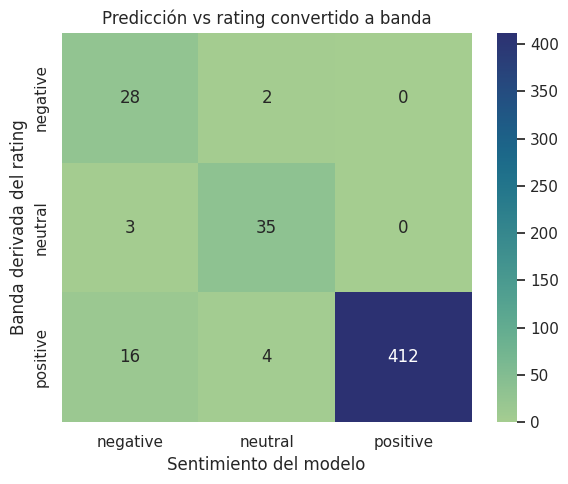

Cambio de distribución positiva (modelo menos rating 4-5): -4.0 puntos porcentuales.


In [8]:
CLASS_LABELS = ["negative", "neutral", "positive"]
y_true = df_results["human_sentiment"]
y_pred = df_results["sentiment"]
metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision_macro": precision_score(y_true, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0),
    "recall_macro": recall_score(y_true, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0),
    "f1_macro": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="macro", zero_division=0),
    "f1_weighted": f1_score(y_true, y_pred, labels=CLASS_LABELS, average="weighted", zero_division=0),
    "human_mean_rating": float(df_results[RATING_COLUMN].mean()),
    "model_mean_stars": float(df_results["predicted_stars"].mean()),
    "human_high_rating_percent": float((df_results[RATING_COLUMN] >= 4).mean() * 100),
    "model_positive_percent": float((df_results["sentiment"] == "positive").mean() * 100),
}
print(pd.Series(metrics).round(4).to_string())
print("\nAcuerdo por clase (ratings mapeados como proxy):")
print(classification_report(y_true, y_pred, labels=CLASS_LABELS, zero_division=0, digits=3))

cm = confusion_matrix(y_true, y_pred, labels=CLASS_LABELS)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="crest", xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS, ax=ax)
ax.set(title="Predicción vs rating convertido a banda", xlabel="Sentimiento del modelo", ylabel="Banda derivada del rating")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "confusion_matrix.png", dpi=140, bbox_inches="tight")
plt.show()

print(f"Cambio de distribución positiva (modelo menos rating 4-5): {metrics['model_positive_percent'] - metrics['human_high_rating_percent']:+.1f} puntos porcentuales.")

## 10. Analizar errores y casos límite

Definimos “falso negativo por rating” como una reseña con 4–5 estrellas humanas clasificada negativa. No equivale necesariamente a un error real de sentimiento: inspeccionaremos el texto para identificar si el rating refleja una experiencia global positiva pese a una queja puntual.

In [9]:
false_negatives = df_results[(df_results[RATING_COLUMN] >= 4) & (df_results["sentiment"] == "negative")].copy()
false_positives = df_results[(df_results[RATING_COLUMN] <= 2) & (df_results["sentiment"] == "positive")].copy()
neutral_disagreements = df_results[(df_results[RATING_COLUMN] == 3) & (df_results["sentiment"] != "neutral")].copy()

print("Rating 4-5 predicho negativo:", len(false_negatives), "de", int((df_results[RATING_COLUMN] >= 4).sum()))
print("Rating 1-2 predicho positivo:", len(false_positives))
print("Rating 3 con banda no neutral:", len(neutral_disagreements))
pd.set_option("display.max_colwidth", 240)
display(false_negatives[["review_id", RATING_COLUMN, "model_label", "score", TEXT_COLUMN]])
display(false_positives[["review_id", RATING_COLUMN, "model_label", "score", TEXT_COLUMN]])
display(neutral_disagreements[["review_id", RATING_COLUMN, "model_label", "score", TEXT_COLUMN]])

# Revisamos además las reseñas cortas, donde una frase aislada puede dominar la predicción.
short_reviews = df_results.assign(text_length=df_results[TEXT_COLUMN].str.len()).nsmallest(10, "text_length")
display(short_reviews[["review_id", RATING_COLUMN, "sentiment", "score", "text_length", TEXT_COLUMN]])

Rating 4-5 predicho negativo: 16 de 432
Rating 1-2 predicho positivo: 0
Rating 3 con banda no neutral: 3


,review_id,rating,model_label,score,review_text
13,14,4,1 star,0.444348,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.
14,15,5,1 star,0.389345,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit."
72,73,5,1 star,0.267875,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.
86,87,5,1 star,0.324705,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!
137,138,5,2 stars,0.275117,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit."
199,200,5,2 stars,0.368520,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.
203,204,5,1 star,0.349168,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit."
253,254,5,1 star,0.364092,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!
269,270,5,1 star,0.409078,Stopped by Harbor House Café for the first time. Our server remembered our names by the second visit. Every dish was bursting with flavor. Great value for what you get. Will definitely be back!
321,322,5,1 star,0.607708,"Every dish was bursting with flavor. The staff seemed annoyed to be there, but honestly the food made up for it. Will definitely be back!"


,review_id,rating,model_label,score,review_text


,review_id,rating,model_label,score,review_text
214,215,3,2 stars,0.404354,"Came to Harbor House Café for a birthday brunch. Average sandwiches, nothing to write home about. Nobody checked on us the entire meal. Wouldn't go out of my way, but wouldn't avoid it either."
310,311,3,2 stars,0.486910,"Tried Harbor House Café after seeing it recommended online. The food was decent, nothing special. Nobody checked on us the entire meal. Might give it another shot."
479,480,3,2 stars,0.432790,"Visited Harbor House Café last weekend. Average sandwiches, nothing to write home about. The staff seemed annoyed to be there. Might give it another shot."


,review_id,rating,sentiment,score,text_length,review_text
415,416,3,neutral,0.844595,86,The coffee was okay. The staff were polite but a bit slow. It's fine for a quick stop.
190,191,2,negative,0.437670,87,The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.
382,383,5,positive,0.677114,92,Service was fast and friendly. The pastries were incredible. Already planning my next visit.
196,197,5,positive,0.745610,97,Service was fast and friendly. The music and decor set the perfect mood. Will definitely be back!
406,407,3,neutral,0.791501,97,"The food was decent, nothing special. Average service, no complaints. Might give it another shot."
498,499,5,positive,0.929645,99,"Best brunch i've had in months. The place has such a cozy, welcoming vibe. Will definitely be back!"
295,296,5,positive,0.652222,100,"The place has such a cozy, welcoming vibe. Service was fast and friendly. This is now my go-to spot."
435,436,5,positive,0.924735,100,Best brunch i've had in months. The music and decor set the perfect mood. This is now my go-to spot.
317,318,5,positive,0.759296,103,The staff were warm and attentive. The coffee was rich and perfectly brewed. This is now my go-to spot.
376,377,3,neutral,0.733485,103,"The menu is fine but a bit repetitive. Service was fine, nothing memorable. Might give it another shot."


### Muestra manual: 20 reseñas

La muestra incluye todos los falsos negativos por rating alto, los tres desacuerdos neutrales y un control negativo alineado. Las notas son una revisión humana cualitativa y no una nueva etiqueta gold.

In [10]:
manual_notes = {
    14: "Positiva: comida y equipo, con intención de volver. 1 estrella contradice claramente el tono.",
    15: "Positiva: ambiente acogedor y próxima visita; falso negativo claro.",
    73: "Positiva: servicio rápido, comida rica y recomendación de valor; falso negativo claro.",
    87: "Positiva: atención a una alergia y promesa explícita de volver; falso negativo claro.",
    138: "Positiva: elogios a la atención, ambiente y retorno; falso negativo claro.",
    200: "Positiva: ambiente, comida y próxima visita; falso negativo claro.",
    204: "Mixta pero globalmente positiva: critica al cajero y dice que la comida lo compensó; el modelo parece anclarse en la queja.",
    254: "Positiva: elogio a la adaptación por alergia y a la experiencia; falso negativo claro.",
    270: "Positiva: atención personal, comida y valor; falso negativo claro.",
    322: "Mixta pero termina recomendando volver; probable sobrerreacción a ‘staff seemed annoyed’.",
    332: "Positiva: adaptación por alergia, café y próxima visita; falso negativo claro.",
    409: "Positiva: comida y servicio, con intención de volver; falso negativo claro.",
    440: "Positiva: comida, atención recordada y valor; falso negativo claro.",
    462: "Positiva: equipo atento, comida y retorno; falso negativo claro.",
    474: "Positiva: comida, servicio y lugar favorito; falso negativo claro.",
    489: "Positiva: comida, equipo y próxima visita; falso negativo claro.",
    215: "Neutral/ligeramente negativa: comida promedio y falta de seguimiento; 2 estrellas es plausible aunque el rating sea 3.",
    311: "Neutral con crítica al servicio: ‘decent’ y ‘might give it another shot’; 2 estrellas plausible.",
    480: "Mixta-negativa: comida promedio y personal molesto; 2 estrellas plausible para un rating 3.",
    191: "Negativa coherente: pedido incorrecto dos veces y duda de regresar; rating 2 y predicción negativa alineados.",
}
manual_review_ids = (
    false_negatives["review_id"].astype(int).tolist()
    + neutral_disagreements["review_id"].astype(int).tolist()
    + [191]
)
manual_sample = df_results[df_results["review_id"].isin(manual_review_ids)].copy()
manual_sample["manual_assessment"] = manual_sample["review_id"].map(manual_notes)
assert len(manual_sample) == 20
assert manual_sample["manual_assessment"].notna().all()
display(manual_sample[["review_id", RATING_COLUMN, "model_label", "sentiment", "score", TEXT_COLUMN, "manual_assessment"]])

,review_id,rating,model_label,sentiment,score,review_text,manual_assessment
13,14,4,1 star,negative,0.444348,Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.,"Positiva: comida y equipo, con intención de volver. 1 estrella contradice claramente el tono."
14,15,5,1 star,negative,0.389345,"Every dish was bursting with flavor. The place has such a cozy, welcoming vibe. Already planning my next visit.",Positiva: ambiente acogedor y próxima visita; falso negativo claro.
72,73,5,1 star,negative,0.267875,Stopped by Harbor House Café for the first time. Service was fast and friendly. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.,"Positiva: servicio rápido, comida rica y recomendación de valor; falso negativo claro."
86,87,5,1 star,negative,0.324705,Tried Harbor House Café after seeing it recommended online. The seasonal menu never disappoints. They went out of their way to accommodate my allergy. Will definitely be back!,Positiva: atención a una alergia y promesa explícita de volver; falso negativo claro.
137,138,5,2 stars,negative,0.275117,"Tried Harbor House Café after seeing it recommended online. They went out of their way to accommodate my allergy. The place has such a cozy, welcoming vibe. Already planning my next visit.","Positiva: elogios a la atención, ambiente y retorno; falso negativo claro."
190,191,2,2 stars,negative,0.437670,The pastry was stale. Our server got our order wrong twice. Not sure I'll be returning.,Negativa coherente: pedido incorrecto dos veces y duda de regresar; rating 2 y predicción negativa alineados.
199,200,5,2 stars,negative,0.368520,Stopped by Harbor House Café for the first time. The music and decor set the perfect mood. Every dish was bursting with flavor. Already planning my next visit.,"Positiva: ambiente, comida y próxima visita; falso negativo claro."
203,204,5,1 star,negative,0.349168,"Came to Harbor House Café for a birthday brunch. Every dish was bursting with flavor. The cashier was rude when i asked about the menu, but honestly the food made up for it. Already planning my next visit.",Mixta pero globalmente positiva: critica al cajero y dice que la comida lo compensó; el modelo parece anclarse en la queja.
214,215,3,2 stars,negative,0.404354,"Came to Harbor House Café for a birthday brunch. Average sandwiches, nothing to write home about. Nobody checked on us the entire meal. Wouldn't go out of my way, but wouldn't avoid it either.",Neutral/ligeramente negativa: comida promedio y falta de seguimiento; 2 estrellas es plausible aunque el rating sea 3.
253,254,5,1 star,negative,0.364092,Stopped by Harbor House Café for the first time. They went out of their way to accommodate my allergy. Great spot to work or catch up with friends. Will definitely be back!,Positiva: elogio a la adaptación por alergia y a la experiencia; falso negativo claro.


## 11. Función reutilizable para nuevas reseñas

La función siguiente reutiliza la misma pipeline cargada, valida texto vacío y devuelve banda, estrellas y score. Los ejemplos manuales son smoke tests del formato, no una evaluación adicional.

In [11]:
def predict_sentiment(texto):
    clean_text = normalize_review(texto)
    if not clean_text:
        raise ValueError("El texto de la reseña no puede estar vacío.")
    result = classifier(
        clean_text,
        truncation=True,
        max_length=512,
    )[0]
    stars = parse_stars(result["label"])
    return {
        "label": STAR_TO_SENTIMENT[stars],
        "stars": stars,
        "score": round(float(result["score"]), 6),
    }


manual_examples = df_results[df_results["review_id"].isin([14, 191, 416])][["review_id", TEXT_COLUMN]]
manual_predictions = [
    {"review_id": row.review_id, **predict_sentiment(row.review_text)}
    for row in manual_examples.itertuples(index=False)
]
assert len(manual_predictions) == 3
assert all(result["label"] in STAR_TO_SENTIMENT.values() for result in manual_predictions)
try:
    predict_sentiment("   ")
except ValueError:
    print("Entrada vacía: rechazada correctamente.")
display(pd.DataFrame(manual_predictions))

Entrada vacía: rechazada correctamente.


,review_id,label,stars,score
0,14,negative,1,0.444348
1,191,negative,2,0.437670
2,416,neutral,3,0.844595


## 12. Guardar resultados y artefactos

El notebook es el informe narrativo; el script `src/app.py` es la ruta de inferencia de producción. Guardamos el dataset con predicción y score, métricas reproducibles y evidencia de revisión manual. Las figuras de EDA y confusión ya están en `reports/figures/`.

In [12]:
df_results.to_csv(OUTPUT_PATH, index=False, encoding="utf-8")
manual_sample.to_csv(REPORTS_PATH / "manual_review_sample.csv", index=False, encoding="utf-8")

metrics_payload = {
    "model": MODEL_ID,
    "revision": MODEL_REVISION,
    "sample_size": int(len(df_results)),
    "human_mean_rating": round(float(df_results[RATING_COLUMN].mean()), 4),
    "model_mean_stars": round(float(df_results["predicted_stars"].mean()), 4),
    "rating_distribution": {str(int(key)): int(value) for key, value in rating_counts.items()},
    "sentiment_distribution": {str(key): int(value) for key, value in sentiment_distribution.items()},
    "metrics_vs_rating_proxy": {key: round(float(value), 6) for key, value in metrics.items()},
    "confusion_labels": CLASS_LABELS,
    "confusion_matrix": cm.tolist(),
    "high_rating_negative_predictions": int(len(false_negatives)),
    "low_rating_positive_predictions": int(len(false_positives)),
    "neutral_rating_disagreements": int(len(neutral_disagreements)),
    "manual_review_count": int(len(manual_sample)),
    "inference_seconds": round(float(inference_seconds), 2),
}
with (REPORTS_PATH / "metrics.json").open("w", encoding="utf-8") as destination:
    json.dump(metrics_payload, destination, ensure_ascii=False, indent=2)

saved_results = pd.read_csv(OUTPUT_PATH)
assert len(saved_results) == 500
assert {"review_id", "rating", "predicted_stars", "sentiment", "model_label", "score"}.issubset(saved_results.columns)
assert saved_results["score"].between(0, 1).all()
assert saved_results["sentiment"].isin(CLASS_LABELS).all()

print("Artefactos guardados:")
for artifact in [OUTPUT_PATH, REPORTS_PATH / "metrics.json", REPORTS_PATH / "manual_review_sample.csv", FIGURES_PATH / "eda_rating_and_length.png", FIGURES_PATH / "confusion_matrix.png"]:
    print(f"- {artifact.relative_to(PROJECT_ROOT)} ({artifact.stat().st_size:,} bytes)")
print("Validación CSV: 500 filas; label/polaridad y scores dentro de rango.")
print("Git (no ejecutado desde el notebook):")
print("git add src/explore.ipynb src/app.py requirements.txt data/raw/reviews.csv data/processed/reviews_with_sentiment.csv reports")
print("git commit -m 'feat: add review sentiment analysis'")
print("git push --set-upstream origin feature/analisis-sentimiento")

Artefactos guardados:
- data/processed/reviews_with_sentiment.csv (194,102 bytes)
- reports/metrics.json (1,106 bytes)
- reports/manual_review_sample.csv (9,433 bytes)
- reports/figures/eda_rating_and_length.png (46,616 bytes)
- reports/figures/confusion_matrix.png (52,591 bytes)
Validación CSV: 500 filas; label/polaridad y scores dentro de rango.
Git (no ejecutado desde el notebook):
git add src/explore.ipynb src/app.py requirements.txt data/raw/reviews.csv data/processed/reviews_with_sentiment.csv reports
git commit -m 'feat: add review sentiment analysis'
git push --set-upstream origin feature/analisis-sentimiento


## 13. Conclusiones para la account manager

- El rating humano medio es **4,50/5**; 86,4% de las reseñas tiene 4–5 estrellas. El modelo clasifica **82,4% positivas, 8,2% neutrales y 9,4% negativas**: la proporción positiva queda 4 puntos porcentuales por debajo de la proporción con rating alto. La media predicha es 4,398 estrellas.
- El acuerdo con las bandas derivadas del rating es 95%, pero ese dato no demuestra precisión real porque el rating no es una etiqueta independiente del sentimiento. La clase negativa tiene solo 30 ejemplos y precision 59,6%; conviene revisar sus casos antes de reportarlos como clientes insatisfechos.
- Se encontraron 16 reseñas de rating 4–5 que el modelo llamó negativas. En la lectura manual, 14 son claramente positivas y dos contienen una queja puntual compensada por una experiencia global positiva. Esto es consistente con el riesgo de desajuste entre reseñas de productos y de servicios, aunque estos datos por sí solos no prueban la causa.
- Recomendación: presentar el resultado como señal de alerta para revisión, no como sustituto del rating 4,5 ni como medición definitiva de satisfacción. Antes de decisiones comerciales, conviene anotar manualmente una muestra representativa más amplia y comparar un modelo validado en reseñas de servicios.

La inferencia reproducible está en `src/app.py`; los pesos no se versionan. Para ejecutar la ruta de producción desde esta carpeta: `python src/app.py`.